In [6]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import AxesGrid
from salvaged import *
# ==========================================
run = '1me9r/'             # experiment name
datadir = '../data/'+run      # location of the data

In [9]:
snapshot = 128
ThisPatch = RamsesMHDPatch
#ThisPatch = Stagger2eMHDPatch
refine_by = 3
to_skip = []
verbose=False
gamma = 1.4
orbit_radius_au = 1.0
omega = [0.0,0.0,1.0]
omega[2] = omega[2]*2.*np.pi*sc.scaling().t/sc.yr
pl_pos= [0.0,1.0,0.0]    
patches = get_data(snap = snapshot,datadir=datadir, ThisPatch=ThisPatch, skip=to_skip)

239 patches collected for snapshot 128


yt : [INFO     ] 2017-04-16 13:11:44,890 Parameters: current_time              = 4360.0
yt : [INFO     ] 2017-04-16 13:11:44,891 Parameters: domain_dimensions         = [48 48 48]
yt : [INFO     ] 2017-04-16 13:11:44,893 Parameters: domain_left_edge          = [ -2405.7000521 -12028.500261   -2405.7000521]
yt : [INFO     ] 2017-04-16 13:11:44,894 Parameters: domain_right_edge         = [  2405.70005213  12028.50026075   2405.70005213]
yt : [INFO     ] 2017-04-16 13:11:44,896 Parameters: cosmological_simulation   = 0.0
yt : [INFO     ] 2017-04-16 13:11:45,599 xlim = -3139.224612 3139.224612
yt : [INFO     ] 2017-04-16 13:11:45,601 ylim = -6278.449223 6278.449223
yt : [INFO     ] 2017-04-16 13:11:45,603 xlim = -3139.224612 3139.224612
yt : [INFO     ] 2017-04-16 13:11:45,604 ylim = -6278.449223 6278.449223
yt : [INFO     ] 2017-04-16 13:11:45,607 Making a fixed resolution buffer of (('gas', 'density')) 2000 by 2000



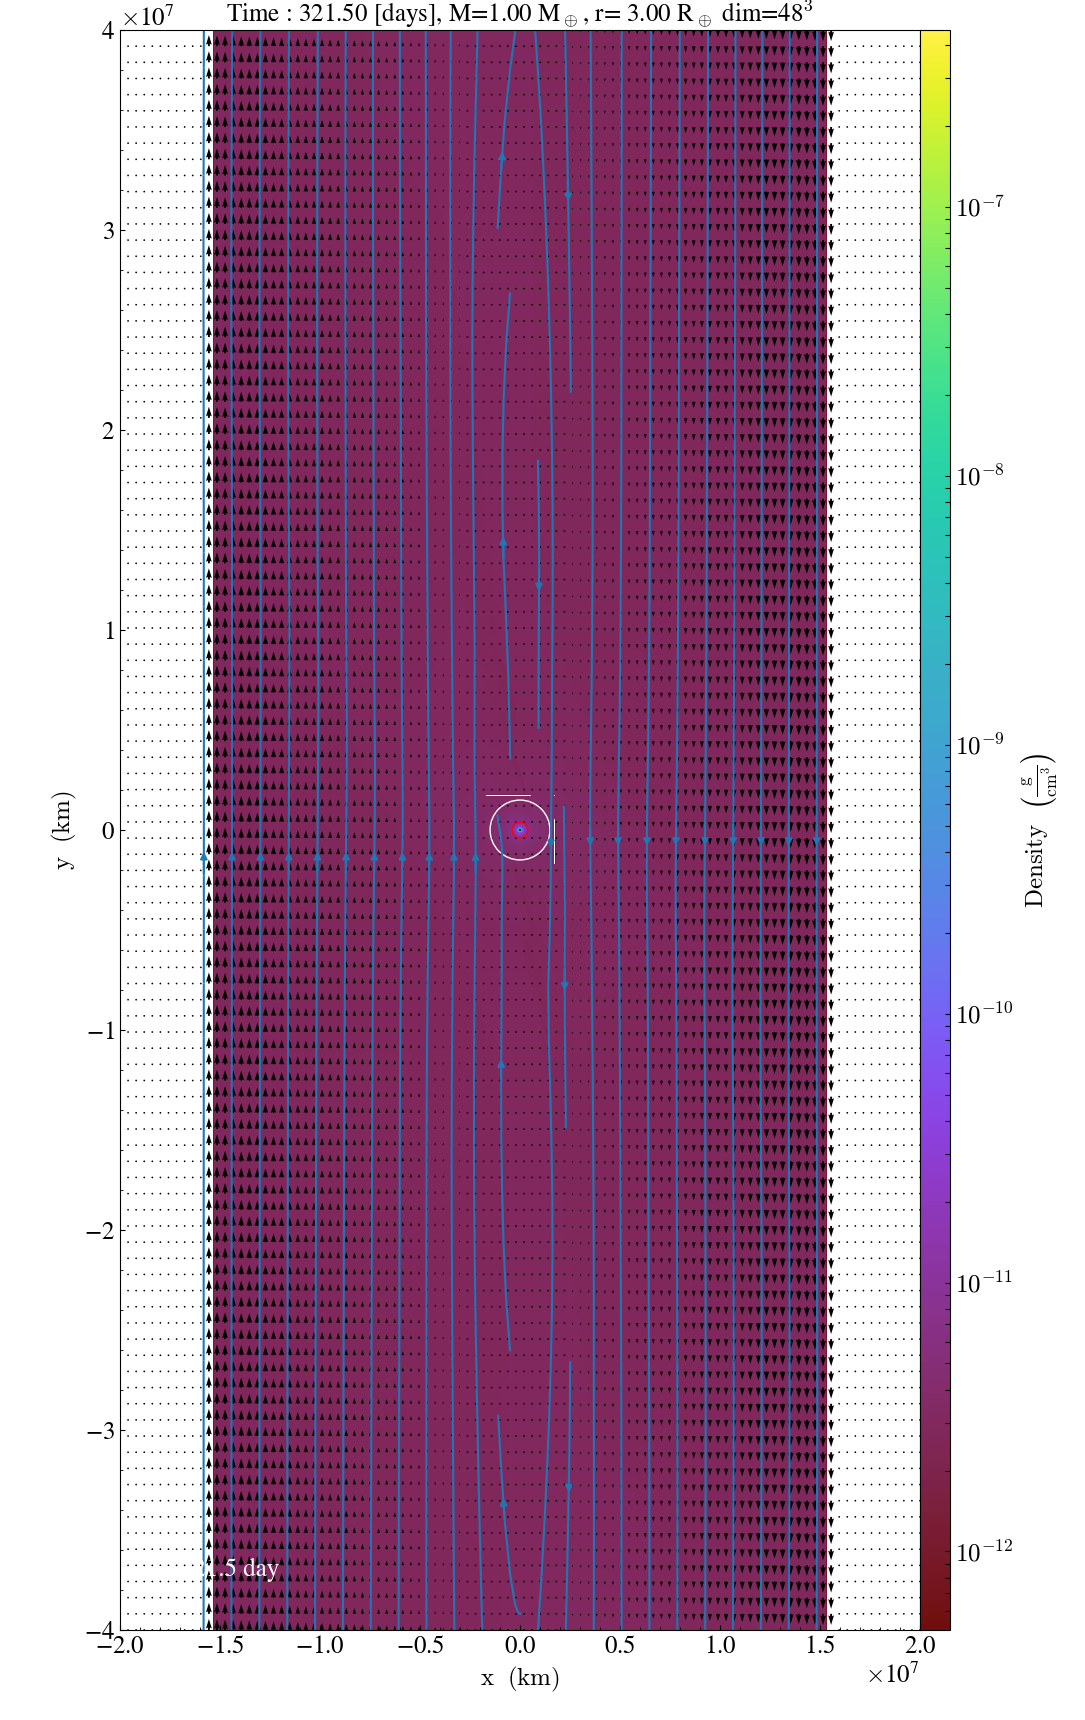

In [16]:
dic=make_yt_dict(patches)
n=patches[0].n
bbox=patches[0].bbox
sz=10000
#pl_rad=1.3480656
pl_rad=1.0
#pl_rad = 0.5376369
rad_mult = 3.0
pl_rad = pl_rad * rad_mult
pl_mass=1.0
csound=1.0
restart_time = 0.
time = patches[0].time+restart_time
bond_rad = pl_mass*sc.scaling().g/csound**2
hill_rad = (pl_mass*sc.scaling().g/(3.*omega[2]**2))**0.333333
ds = load_yt(dic,n,bbox=bbox, time=time, refine_by=refine_by)

slc=yt.SlicePlot(ds=ds,axis="z",fields=["density"],center=[0,0,0],width = ((4e7,'km'),(8e7,'km')))
# == Annotate velocity quivers and streamlines. ==
slc.annotate_velocity(factor=20, normalize=False)
slc.annotate_streamlines('velocity_x', 'velocity_y', factor=20,field_color=None)
# == A bunch of spheres, representing different radii
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=1, circle_args={'color':'magenta'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=pl_rad, circle_args={'color':'black'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=bond_rad, circle_args={'color':'red'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=hill_rad, circle_args={'color':'white'})
# == TITLE ==
slc.annotate_title("Time : {:.2f} [days], M={:.2f} M$_\oplus$, r= {:.2f} R$_\oplus$ dim={:d}$^3$".format((patches[0].time+restart_time)*sc.scaling().t/3600./24., pl_mass, pl_rad, int(n[0])))
#slc.set_zlim('density',6e-12,3e-11)
# == Timestamp ==
slc.current_time=patches[0].time*sc.scaling().t/3600./24.
slc.annotate_timestamp()
#slc.zoom(10)
#slc.annotate_grids(alpha=0.9, draw_ids=False)
#slc.annotate_timestamp()
slc.show()

yt : [INFO     ] 2017-04-16 13:11:55,260 Making a fixed resolution buffer of (('gas', 'density')) 2000 by 2000



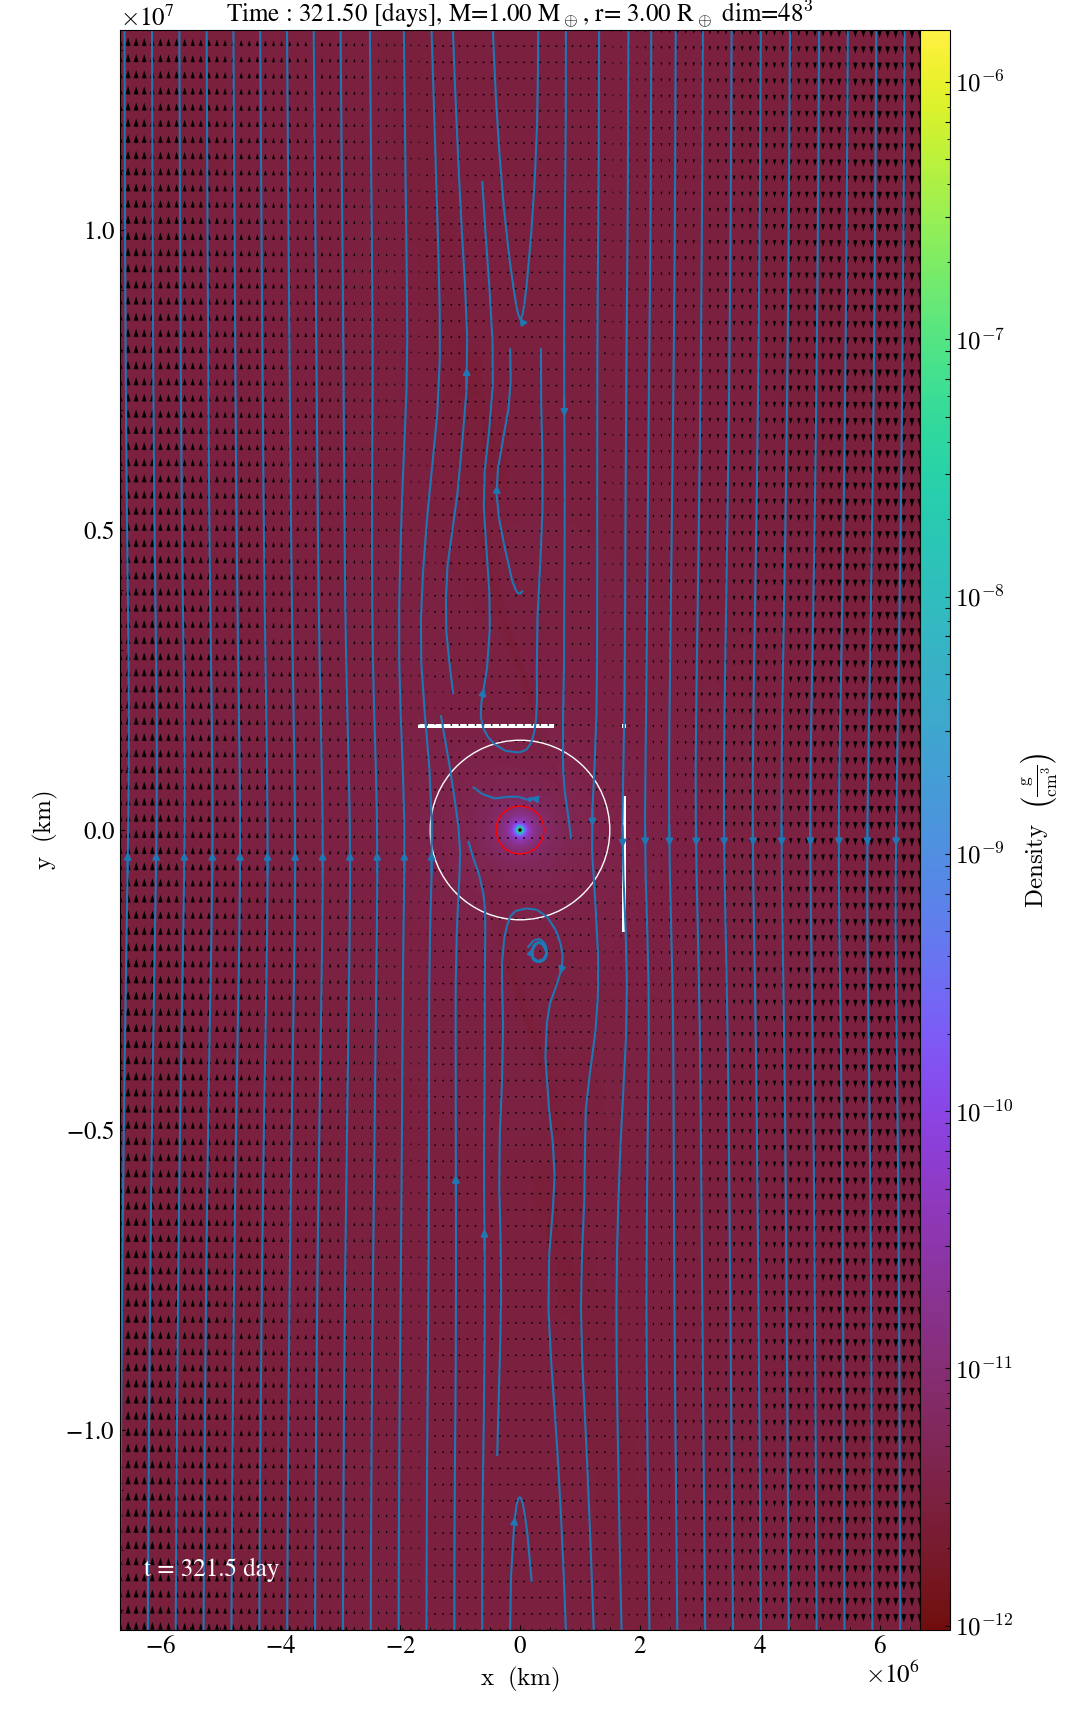

In [17]:
slc.zoom(3)
#slc.set_zlim('temperature',100,2000)
#slc.set_zlim('density',1e-12,1e-9)
#slc.set_zlim('e',8e-14,2e-11)
#slc.annotate_grids()
slc.show()

In [38]:
def load_long_yt(dc,nx,sz=100,refine_by=3,geometry="cartesian",mass_unit=sc.scaling().m,length_unit=sc.scaling().l,
            time_unit=sc.scaling().t,velocity_unit=sc.scaling().v,periodicity=(False,False,False),time=0):
    ds=yt.load_amr_grids(dc,nx,
                       bbox=np.array([[-sz,sz],[-sz*3,sz*3],[-sz,sz]]),
                       refine_by=3,
                       geometry="cartesian",
                       mass_unit=sc.scaling().m,
                       length_unit=(sc.scaling().l,"km"),
                       velocity_unit=sc.scaling().v,
                       time_unit=sc.scaling().t,
                       sim_time = time,
                       periodicity=(False,False,False))
    return ds

In [ ]:
my_ray = ds.ortho_ray(0,(0,0))
ray_sort = np.argsort(my_ray["t"])
density = my_ray["density"][ray_sort]

yt : [INFO     ] 2017-04-07 16:53:50,071 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



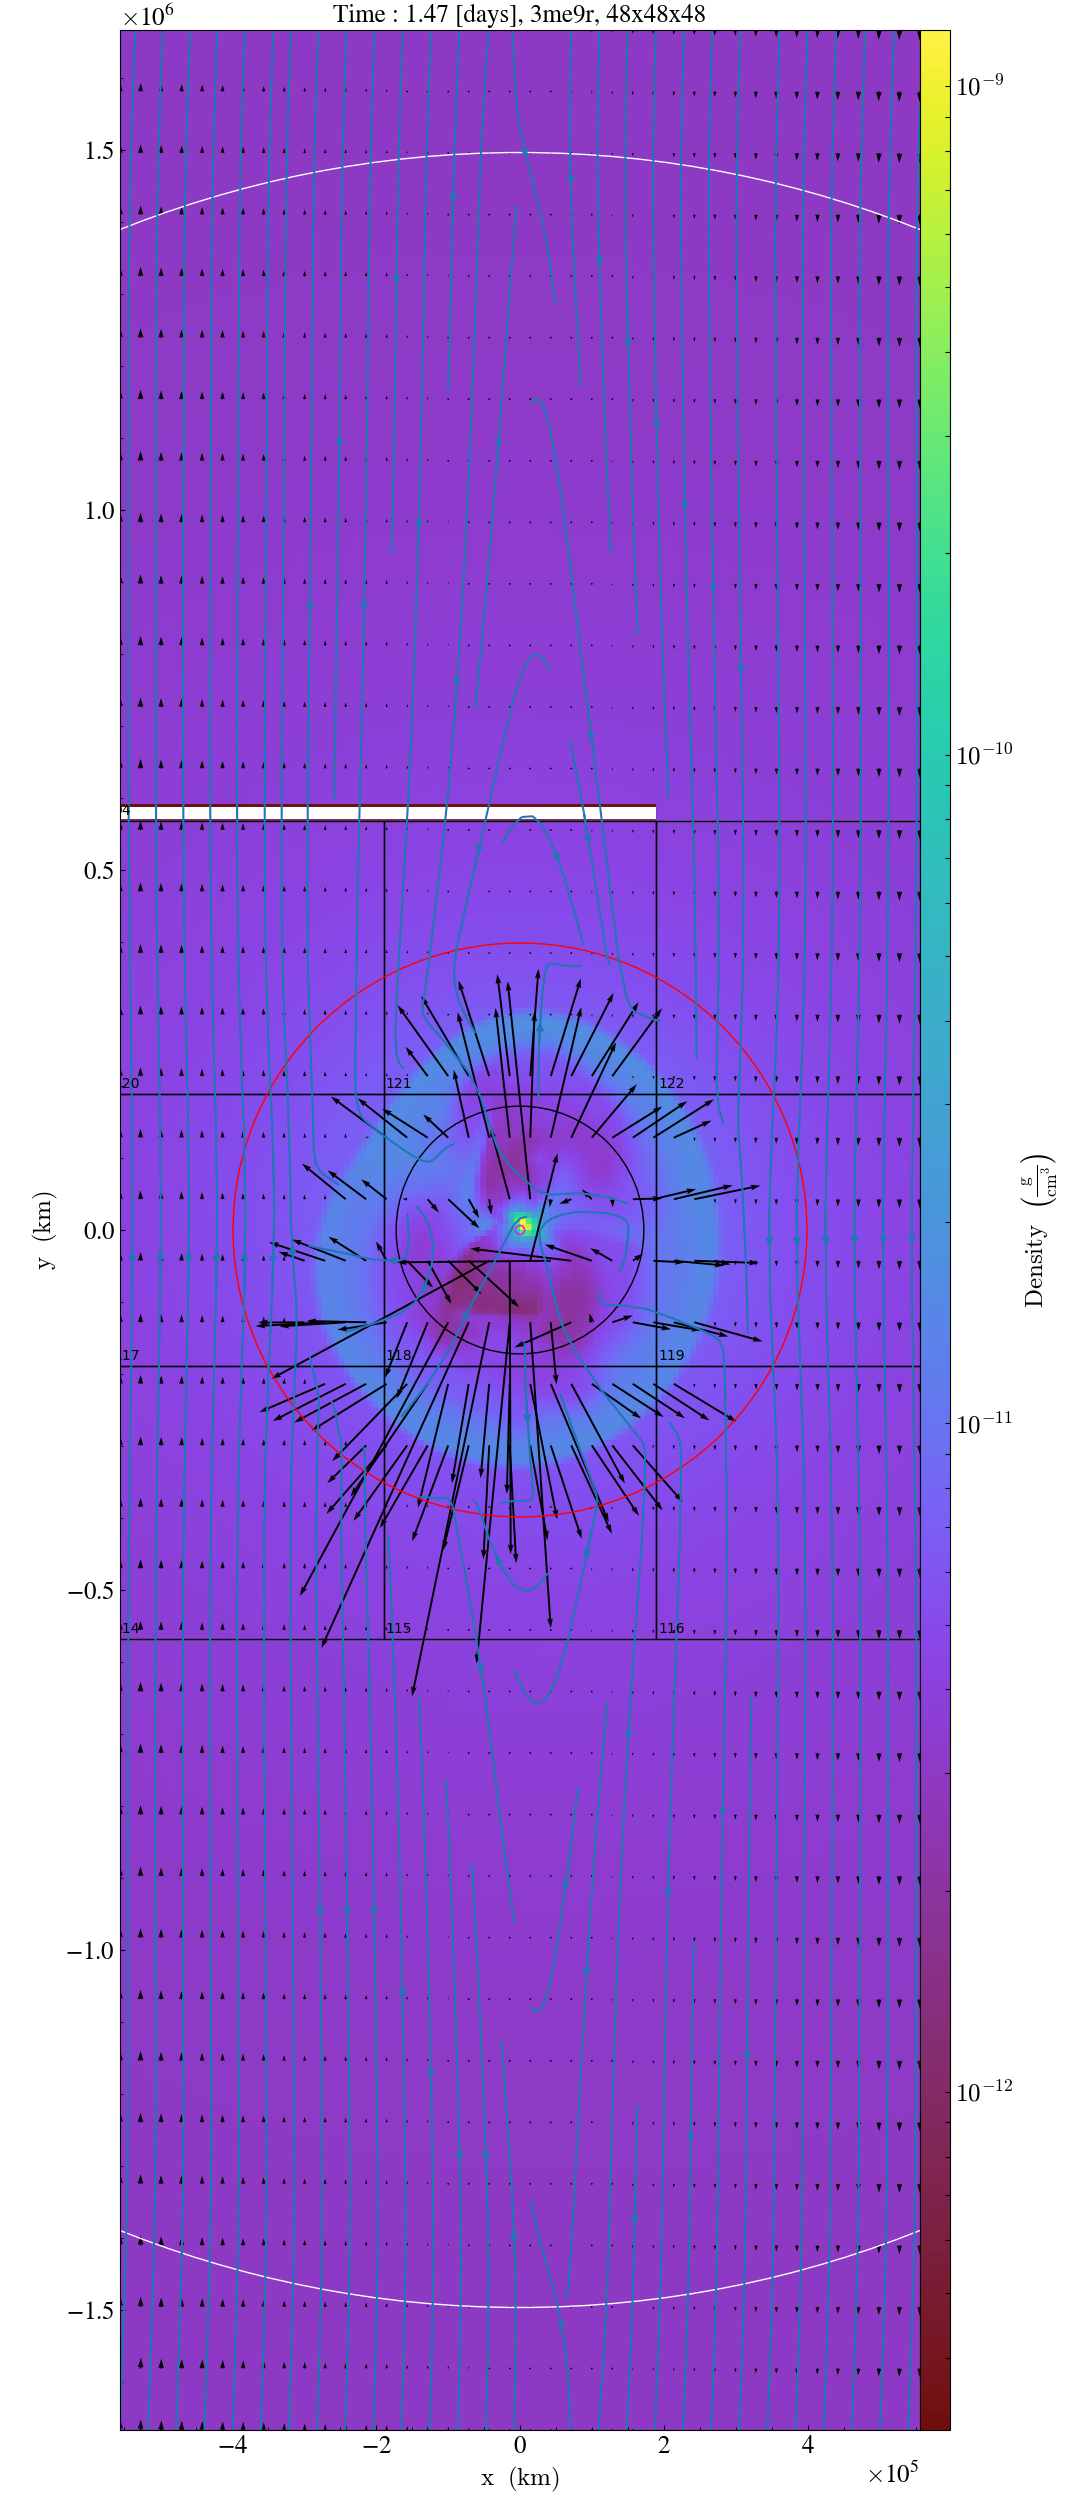

In [116]:
slc.zoom(3)
#slc.set_zlim('temperature',150,250)
#slc.set_zlim('density',2.5e-12,3.5e-12)
#slc.set_zlim('e',8e-14,2e-11)
#slc.annotate_grids()
slc.show()

In [6]:
sc.scaling().temp

242.2828999782719

In [16]:
ee=ds.all_data()

In [120]:
patches[0].velx.max()

3.2248369308263136e-08

In [12]:
gn =patches[0].gn; ng = patches[0].nghost

In [13]:
u=[a-b for a,b in zip(gn,ng)]

In [21]:
om = omega[2] * np.pi* sc.scaling().t / sc.yr
d0 = 3e-12

om

In [68]:
patches[0].time

1080.0

In [107]:
patches[114].id

119

In [3]:
snap = 15

In [5]:
"*%.4i.txt"%snap

'*0015.txt'